# Comparative Evaluation of SMOTE-based Random Forest and XGBoost for Fraud Detection in Mobile Money Payment Systems

**Postgraduate Diploma in Data Analytics** | PDDA0801  
**Nathaniel Luis** | ST10181416 | Research Project | RPDA8412  
**Supervisor:** T. Chinamasa | IIE Emeris | 2026

---

## Purpose
This notebook contains the full analysis for the research report. It compares Random Forest and XGBoost for fraud detection, each trained on the original imbalanced data and on SMOTE-NC-balanced data, and evaluates all four models on the same untouched test set.

## Research questions
- **RQ1:** To what extent does SMOTE improve the fraud detection performance of Random Forest and XGBoost compared to training on the original data?
- **RQ2:** How do Random Forest and XGBoost compare in overall efficacy for detecting mobile money fraud?
- **RQ3:** How do they differ on Precision, Recall, F1-score and AUC-ROC?

## Data
PaySim synthetic mobile money dataset (Lopez-Rojas, 2016), 6,362,620 transactions.
Source: https://www.kaggle.com/datasets/ealaxi/paysim1

## Notebook structure
1. Setup and library versions
2. Data loading and exploratory data analysis
3. Preprocessing (TRANSFER/CASH_OUT filter, encoding, stratified 80/20 split)
4. SMOTE-NC resampling (training data only)
5. Model training (Models A–D)
6. Evaluation (metrics, confusion matrices, ROC and PR curves)
7. McNemar's tests
8. Feature importances

## Reproducibility
- `random_state = 42` throughout
- Library versions are printed in the first code cell
- Figures are saved to `figures/`; splits and predictions to `data/`
- Note: Model B (Random Forest + SMOTE-NC) takes about 25 minutes to train on a laptop CPU

In [1]:
%pip install pandas scikit-learn imbalanced-learn xgboost matplotlib seaborn statsmodels kagglehub joblib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np

SEED = 42
np.random.seed(SEED)

import kagglehub, glob, os
folder = kagglehub.dataset_download("ealaxi/paysim1")
DATA_PATH = glob.glob(os.path.join(folder, "*.csv"))[0]

dtypes = {
    "step": "int16", "type": "category", "amount": "float32",
    "nameOrig": "string", "oldbalanceOrg": "float32", "newbalanceOrig": "float32",
    "nameDest": "string", "oldbalanceDest": "float32", "newbalanceDest": "float32",
    "isFraud": "int8", "isFlaggedFraud": "int8",
}
df = pd.read_csv(DATA_PATH, dtype=dtypes)

print(df.shape)  # expect (6362620, 11)
print(df.memory_usage(deep=True).sum() / 1e9, "GB in memory")
df.head()

(6362620, 11)
0.394254245 GB in memory


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.639648,C1231006815,170136.0,160296.359375,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.280029,C1666544295,21249.0,19384.720703,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.000000,C1305486145,181.0,0.000000,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.000000,C840083671,181.0,0.000000,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.139648,C2048537720,41554.0,29885.859375,M1230701703,0.0,0.0,0,0


In [3]:
import os
os.makedirs("figures", exist_ok=True)

print("Shape:", df.shape)
print("\nMissing values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Shape: (6362620, 11)

Missing values per column:
 step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Duplicate rows: 0


In [4]:
counts = df["isFraud"].value_counts()
print(counts)
print(f"Fraud rate: {counts[1] / len(df) * 100:.4f}%")
print(f"Imbalance ratio: {counts[0] / counts[1]:.0f}:1")

isFraud
0    6354407
1       8213
Name: count, dtype: int64
Fraud rate: 0.1291%
Imbalance ratio: 774:1


In [5]:
by_type = pd.crosstab(df["type"], df["isFraud"], margins=True)
print(by_type)

# How well did the simulator's own rule catch fraud? (Supports dropping isFlaggedFraud)
print(pd.crosstab(df["isFlaggedFraud"], df["isFraud"]))

isFraud         0     1      All
type                            
CASH_IN   1399284     0  1399284
CASH_OUT  2233384  4116  2237500
DEBIT       41432     0    41432
PAYMENT   2151495     0  2151495
TRANSFER   528812  4097   532909
All       6354407  8213  6362620
isFraud               0     1
isFlaggedFraud               
0               6354407  8197
1                     0    16


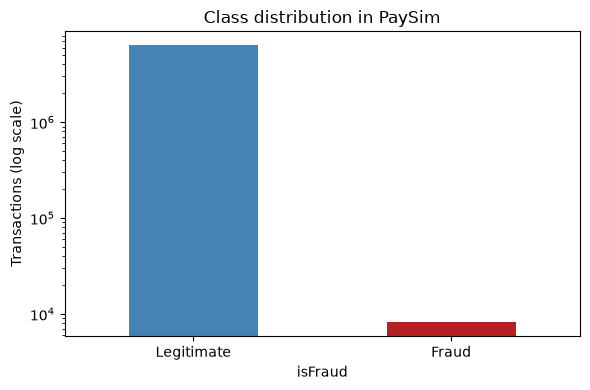

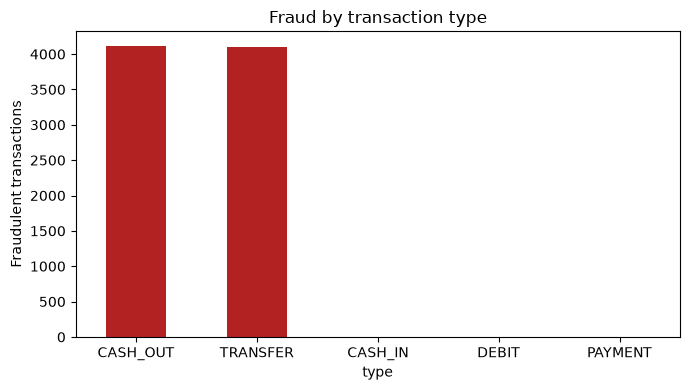

C:\Users\Nathaniel Luis\AppData\Local\Temp\ipykernel_26944\945339140.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Legitimate", "Fraud"])


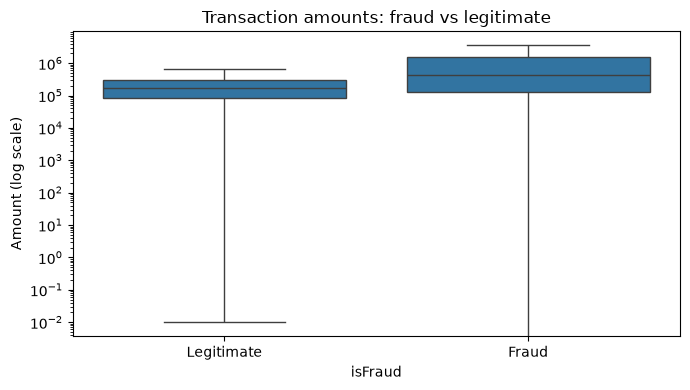

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Figure 1: class distribution (log scale, or the fraud bar is invisible)
fig, ax = plt.subplots(figsize=(6, 4))
counts.plot(kind="bar", ax=ax, logy=True, color=["steelblue", "firebrick"])
ax.set_xticklabels(["Legitimate", "Fraud"], rotation=0)
ax.set_ylabel("Transactions (log scale)")
ax.set_title("Class distribution in PaySim")
plt.tight_layout(); plt.savefig("figures/fig1_class_distribution.png", dpi=300); plt.show()

# Figure 2: fraud count by transaction type
fig, ax = plt.subplots(figsize=(7, 4))
df[df["isFraud"] == 1]["type"].value_counts().plot(kind="bar", ax=ax, color="firebrick")
ax.set_ylabel("Fraudulent transactions")
ax.set_title("Fraud by transaction type")
plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig("figures/fig2_fraud_by_type.png", dpi=300); plt.show()

# Figure 3: amount distribution, fraud vs legitimate (TRANSFER and CASH_OUT only)
sub = df[df["type"].isin(["TRANSFER", "CASH_OUT"])]
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(x="isFraud", y="amount", data=sub, ax=ax, showfliers=False)
ax.set_yscale("log")
ax.set_xticklabels(["Legitimate", "Fraud"])
ax.set_ylabel("Amount (log scale)")
ax.set_title("Transaction amounts: fraud vs legitimate")
plt.tight_layout(); plt.savefig("figures/fig3_amount_boxplot.png", dpi=300); plt.show()

In [7]:
print(df[df["amount"] == 0].groupby("isFraud").size())

isFraud
1    16
dtype: int64


In [8]:
print(((df["amount"] == 0) & (df["isFlaggedFraud"] == 1)).sum())

0


In [9]:
from sklearn.model_selection import train_test_split

# Keep only the transaction types where fraud occurs
model_df = df[df["type"].isin(["TRANSFER", "CASH_OUT"])].copy()
model_df["type"] = model_df["type"].cat.remove_unused_categories()

# Drop identifiers, time index, and the simulator's rule-based flag
model_df = model_df.drop(columns=["nameOrig", "nameDest", "step", "isFlaggedFraud"])

# One-hot encode transaction type
model_df = pd.get_dummies(model_df, columns=["type"], dtype="int8")

# Numbers for your methodology section
n = len(model_df)
n_fraud = model_df["isFraud"].sum()
print(f"Modelling subset: {n:,} rows, {n_fraud:,} fraud ({n_fraud / n * 100:.3f}%)")
print(f"Imbalance ratio: {(n - n_fraud) / n_fraud:.1f}:1")
print(model_df.columns.tolist())

Modelling subset: 2,770,409 rows, 8,213 fraud (0.296%)
Imbalance ratio: 336.3:1
['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'type_CASH_OUT', 'type_TRANSFER']


In [10]:
X = model_df.drop(columns=["isFraud"])
y = model_df["isFraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

for name, target in [("Train", y_train), ("Test", y_test)]:
    print(f"{name}: {len(target):,} rows, {target.sum():,} fraud ({target.mean() * 100:.3f}%)")

Train: 2,216,327 rows, 6,570 fraud (0.296%)
Test: 554,082 rows, 1,643 fraud (0.297%)


In [11]:
import gc
del df, model_df
gc.collect()

2113

In [12]:
from imblearn.over_sampling import SMOTENC
import joblib

type_cols = ["type_CASH_OUT", "type_TRANSFER"]
cat_idx = [X_train.columns.get_loc(c) for c in type_cols]

smote = SMOTENC(categorical_features=cat_idx, random_state=SEED)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("Train before:", y_train.value_counts().to_dict())
print("Train after: ", y_train_sm.value_counts().to_dict())
print("Type values after SMOTE-NC:", np.unique(X_train_sm[type_cols].values))
print("Test (untouched):", y_test.value_counts().to_dict())

# Save so a kernel restart doesn't mean redoing everything
os.makedirs("data", exist_ok=True)
joblib.dump((X_train, y_train, X_train_sm, y_train_sm, X_test, y_test), "data/splits.joblib")

Train before: {0: 2209757, 1: 6570}
Train after:  {0: 2209757, 1: 2209757}
Type values after SMOTE-NC: [0 1]
Test (untouched): {0: 552439, 1: 1643}


['data/splits.joblib']

In [13]:
import time
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

def make_model(algo):
    if algo == "RF":
        return RandomForestClassifier(random_state=SEED, n_jobs=-1)
    return XGBClassifier(random_state=SEED, n_jobs=-1)

datasets = {
    "Original": (X_train, y_train),
    "SMOTE-NC": (X_train_sm, y_train_sm),
}

runs = {}
for algo in ["RF", "XGB"]:
    for data_name, (Xtr, ytr) in datasets.items():
        key = f"{algo} | {data_name}"
        model = make_model(algo)

        t0 = time.perf_counter()
        model.fit(Xtr, ytr)
        train_s = time.perf_counter() - t0

        runs[key] = {
            "pred": model.predict(X_test),
            "proba": model.predict_proba(X_test)[:, 1],
            "train_seconds": train_s,
            "importances": pd.Series(model.feature_importances_, index=X_test.columns),
        }
        print(f"{key}: trained in {train_s / 60:.1f} min")

        del model
        gc.collect()

joblib.dump(runs, "data/predictions.joblib")

RF | Original: trained in 5.3 min
RF | SMOTE-NC: trained in 24.3 min
XGB | Original: trained in 0.5 min
XGB | SMOTE-NC: trained in 1.0 min


['data/predictions.joblib']

In [14]:
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix)

# If the kernel restarted: runs = joblib.load("data/predictions.joblib")
#                          X_train, y_train, X_train_sm, y_train_sm, X_test, y_test = joblib.load("data/splits.joblib")

labels = {"RF | Original": "A", "RF | SMOTE-NC": "B", "XGB | Original": "C", "XGB | SMOTE-NC": "D"}

rows = []
for key, r in runs.items():
    tn, fp, fn, tp = confusion_matrix(y_test, r["pred"]).ravel()
    rows.append({
        "Model": labels[key], "Configuration": key,
        "Precision": precision_score(y_test, r["pred"]),
        "Recall": recall_score(y_test, r["pred"]),
        "F1": f1_score(y_test, r["pred"]),
        "AUC-ROC": roc_auc_score(y_test, r["proba"]),
        "PR-AUC": average_precision_score(y_test, r["proba"]),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Train (min)": r["train_seconds"] / 60,
    })

results = pd.DataFrame(rows).set_index("Model")
results.round(4).to_csv("figures/table_results.csv")
results.round(4)

,Configuration,Precision,Recall,F1,AUC-ROC,PR-AUC,TP,FP,FN,TN,Train (min)
Model,,,,,,,,,,,
A,RF | Original,0.9638,0.7785,0.8613,0.9923,0.9275,1279,48,364,552391,5.2703
B,RF | SMOTE-NC,0.6442,0.9556,0.7696,0.9985,0.9331,1570,867,73,551572,24.2742
C,XGB | Original,0.8341,0.6762,0.7469,0.9287,0.7096,1111,221,532,552218,0.5394
D,XGB | SMOTE-NC,0.4562,0.9909,0.6247,0.9985,0.9504,1628,1941,15,550498,0.9766


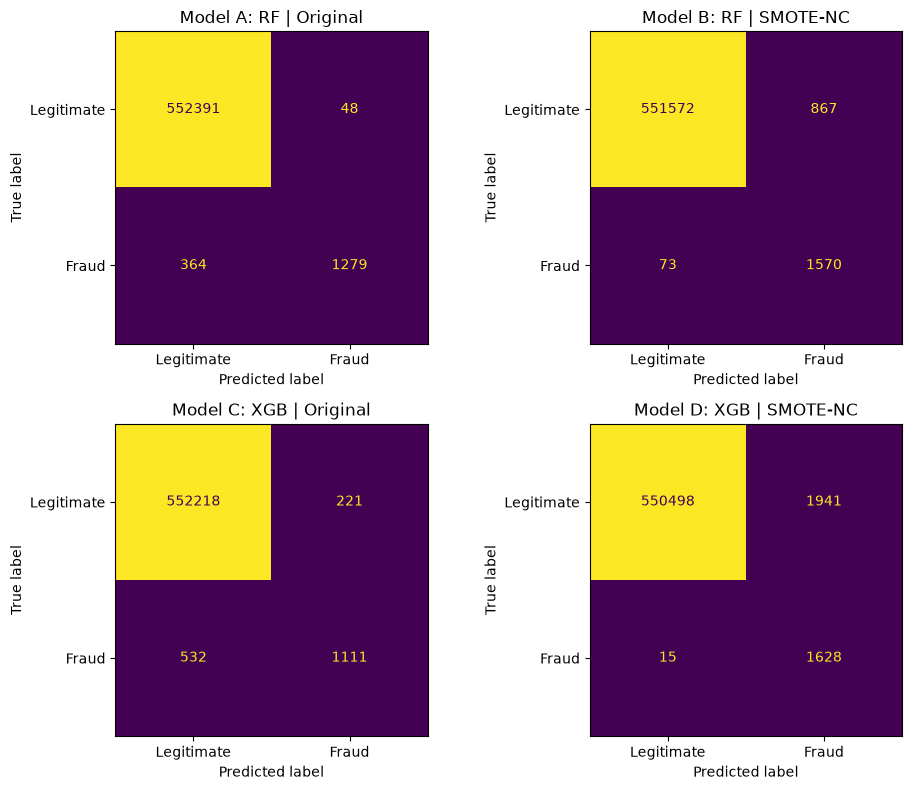

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (key, r) in zip(axes.ravel(), runs.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, r["pred"], ax=ax, values_format="d", colorbar=False,
        display_labels=["Legitimate", "Fraud"])
    ax.set_title(f"Model {labels[key]}: {key}")
plt.tight_layout(); plt.savefig("figures/fig4_confusion_matrices.png", dpi=300); plt.show()

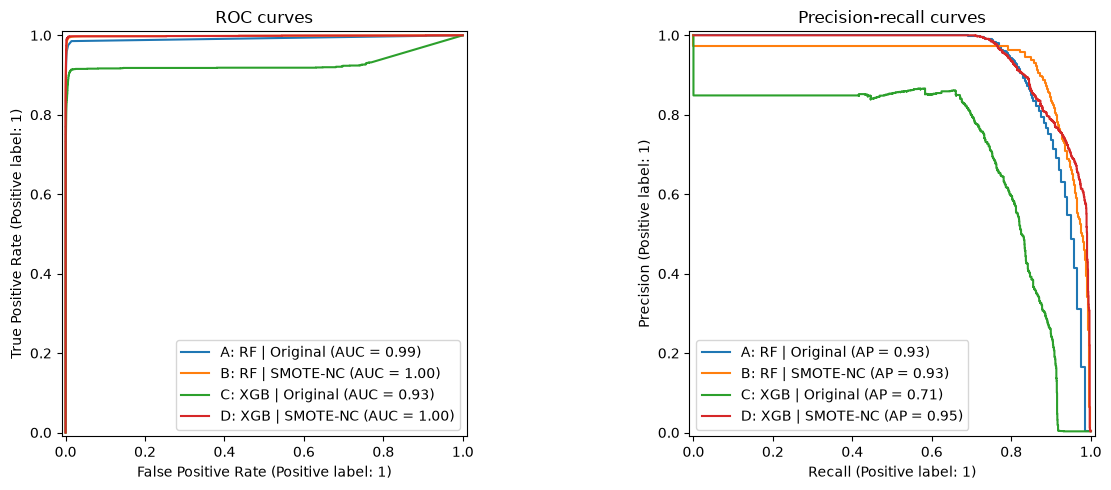

In [16]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for key, r in runs.items():
    name = f"{labels[key]}: {key}"
    RocCurveDisplay.from_predictions(y_test, r["proba"], name=name, ax=ax1)
    PrecisionRecallDisplay.from_predictions(y_test, r["proba"], name=name, ax=ax2)
ax1.set_title("ROC curves"); ax2.set_title("Precision-recall curves")
plt.tight_layout(); plt.savefig("figures/fig5_roc_pr_curves.png", dpi=300); plt.show()

In [17]:
from statsmodels.stats.contingency_tables import mcnemar

def mcnemar_test(a, b):
    ca = runs[a]["pred"] == y_test.values
    cb = runs[b]["pred"] == y_test.values
    table = [[np.sum(ca & cb), np.sum(ca & ~cb)],
             [np.sum(~ca & cb), np.sum(~ca & ~cb)]]
    discordant = table[0][1] + table[1][0]
    res = mcnemar(table, exact=discordant < 25, correction=True)
    return table, res

pairs = [
    ("RF | SMOTE-NC", "XGB | SMOTE-NC", "PRIMARY (hypothesis): B vs D"),
    ("RF | Original", "RF | SMOTE-NC", "RQ1 supplementary: A vs B"),
    ("XGB | Original", "XGB | SMOTE-NC", "RQ1 supplementary: C vs D"),
]
for a, b, label in pairs:
    table, res = mcnemar_test(a, b)
    print(f"\n{label}")
    print(f"  {a} right, {b} wrong: {table[0][1]:,}")
    print(f"  {a} wrong, {b} right: {table[1][0]:,}")
    print(f"  statistic = {res.statistic:.3f}, p-value = {res.pvalue:.4g}")


PRIMARY (hypothesis): B vs D
  RF | SMOTE-NC right, XGB | SMOTE-NC wrong: 1,230
  RF | SMOTE-NC wrong, XGB | SMOTE-NC right: 214
  statistic = 713.452, p-value = 3.552e-157

RQ1 supplementary: A vs B
  RF | Original right, RF | SMOTE-NC wrong: 821
  RF | Original wrong, RF | SMOTE-NC right: 293
  statistic = 249.308, p-value = 3.676e-56

RQ1 supplementary: C vs D
  XGB | Original right, XGB | SMOTE-NC wrong: 1,904
  XGB | Original wrong, XGB | SMOTE-NC right: 701
  statistic = 554.627, p-value = 1.24e-122


                A: RF | Original  B: RF | SMOTE-NC  C: XGB | Original  \
amount                    0.1719            0.1763             0.5654   
oldbalanceOrg             0.2946            0.4335             0.2000   
newbalanceOrig            0.0509            0.0619             0.0248   
oldbalanceDest            0.1008            0.0910             0.1554   
newbalanceDest            0.2421            0.1793             0.0443   
type_CASH_OUT             0.0672            0.0288             0.0101   
type_TRANSFER             0.0725            0.0291             0.0000   

                D: XGB | SMOTE-NC  
amount                     0.0969  
oldbalanceOrg              0.2956  
newbalanceOrig             0.4284  
oldbalanceDest             0.0079  
newbalanceDest             0.1100  
type_CASH_OUT              0.0611  
type_TRANSFER              0.0000  


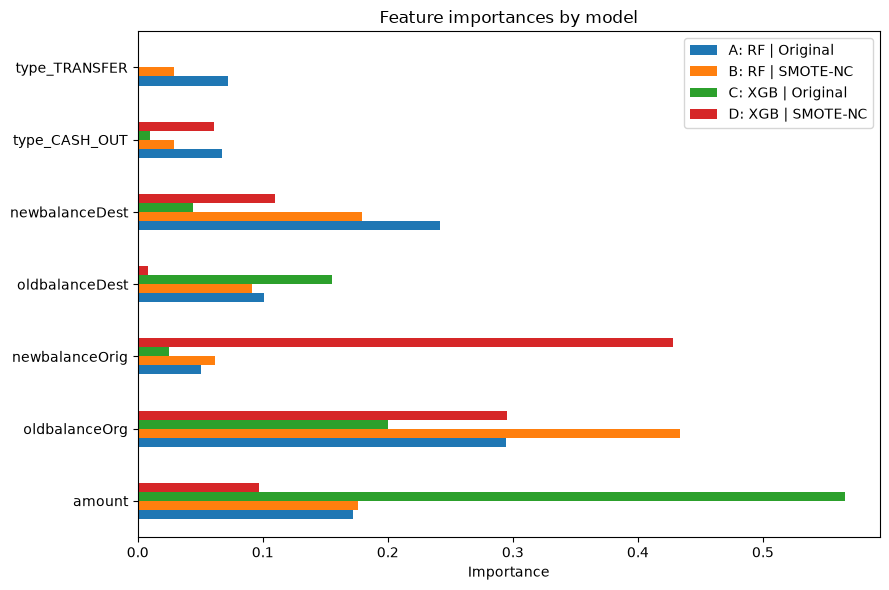

In [18]:
imp = pd.DataFrame({f"{labels[k]}: {k}": r["importances"] for k, r in runs.items()})
print(imp.round(4))

ax = imp.plot(kind="barh", figsize=(9, 6))
ax.set_xlabel("Importance"); ax.set_title("Feature importances by model")
plt.tight_layout(); plt.savefig("figures/fig6_feature_importances.png", dpi=300); plt.show()

In [3]:
   df.groupby('isFraud')['amount'].median()

isFraud
0     74684.71875
1    441423.43750
Name: amount, dtype: float32